# 🏛️    UNIVERSIDAD NACIONAL DE SAN ANTONIO ABAD DEL CUSCO
### Facultad de Ingeniería Civil — Laboratorio de Materiales y Concreto
**Asignatura:** Tecnología del Concreto (IC152)  
**Docente:** ______________________________ | **Grupo / Brigada:** ______________________________  
**Semestre:** 2026-II  

---

# 🔬 PRÁCTICA N.° 11 (TC-11): Refrentado y Rotura a Compresión de Briquetas de Concreto ($f'_c$)
### Cuaderno Interactivo de Procesamiento y Control Normativo

> **Normativa Técnica Aplicable:**  
> **NTP 339.034:2025 (ASTM C39-23)** | **NTP 339.037:2026 (ASTM C617-15)** | **ASTM C1231-23** | **RNE E.060 num. 5.6.3.3**

---

### 🎯 Objetivos de la Práctica
1. Controlar el refrentado con yeso de alta resistencia (espesor <= 6 mm, planitud <= 0,05 mm, cubos >= 35 MPa) o neopreno como alternativa.
2. Calcular esfuerzos corregidos por esbeltez (solo cuando L/D <= 1,75 según ASTM C39 num. 9.2) para las 6 probetas (3 a 7 días y 3 a 28 días).
3. Verificar dispersión entre cilindros compañeros (ASTM C39 num. 11.1.1) y el doble criterio de aceptación RNE E.060.

## ⚙️ 1. Conexión con el Motor de Cálculo (`civillab_unsaac`)
Presiona **Ejecutar (▶)** en la siguiente celda antes de comenzar. Conecta las fórmulas normativas de la UNSAAC, tablas y graficadores.

In [ ]:
# CIVILLAB_WEB_PRELOAD: prepara el navegador (solo versión web)
%pip install -q openpyxl


In [1]:
# ==============================================================================
# CONEXIÓN CON LA LIBRERÍA DEL LABORATORIO (Ejecutar primero, no modificar)
# ==============================================================================
try:
    import civillab_unsaac as lab
except ModuleNotFoundError:
    # Si la librería aún no está instalada, la ubicamos automáticamente en el proyecto
    import sys
    from pathlib import Path
    raices = [
        Path.cwd(),
        *list(Path.cwd().parents)[:3],
        Path.cwd() / "08_SOFTWARE_LABORATORIO",
        Path.cwd() / "0003_UNSAAC_DOCENCIA" / "08_SOFTWARE_LABORATORIO",
    ]
    for r in raices:
        if (r / "civillab_unsaac").is_dir():
            sys.path.insert(0, str(r))
            break
    import civillab_unsaac as lab

from pathlib import Path
from civillab_unsaac import *
import matplotlib
try:
    get_ipython()
except NameError:
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

try:
    from IPython.display import display
except ImportError:
    display = print

# Carpeta limpia para gráficos y fichas Excel de salida
_pkg_root = Path(lab.__file__).resolve().parents[1]
DIR_SALIDA = (_pkg_root / "fichas_generadas") if (_pkg_root / "notebooks").is_dir() else (Path.cwd() / "fichas_generadas")
DIR_SALIDA.mkdir(parents=True, exist_ok=True)

print("✓ Suite CivilLab UNSAAC conectada y lista para calcular.")

✓ Suite CivilLab UNSAAC conectada y lista para calcular.


---
## 📊 2. Ingreso de Datos de Prensa Hidráulica (6 Probetas de TC-10)
Ingresa las dimensiones promedio (aprox. 0,25 mm) y la carga máxima de rotura en **kgf** o **kN**.


=== EVALUACIÓN NORMATIVA — RESISTENCIA A COMPRESIÓN f'c (ASTM C39-23 / RNE E.060) ===
Diseño: f'c = 210 kg/cm² | Edad de control: 28 días
Fecha vaciado: 2026-10-14 | Fecha ensayo: 2026-11-11
Probetas ensayadas a 28 días: 3

ESTADÍSTICAS DEL LOTE (28 DÍAS):
• Resistencia promedio: 241.4 kg/cm² (23.7 MPa | 115.0% f'c)
• Desviación estándar (s): 6.0 kg/cm² | Coeficiente de variación (CV): 2.5 %
• Rango entre probetas compañeras (ASTM C39 num. 11.1.1, laboratorio): 4.8 % (Límite un operador: <= 7.8 %) -> CONFORME

EVALUACIÓN DE ACEPTACIÓN SEGÚN RNE E.060 (num. 5.6.3.3):
1. Promedio >= f'c (241.4 >= 210): CONFORME
2. Ningún ensayo < límite individual (234.8 >= 175.0): CONFORME

DICTAMEN ESTRUCTURAL: APROBADO — CONCRETO CONFORME

[OK] Ficha Excel de compresión generada: fichas_generadas\TC-11_Ficha_Rotura_fc210.xlsx


,codigo,edad_dias,diametro_mm,altura_mm,esbeltez_ld,factor_ld,carga_kN,fc_mpa,fc_kg_cm2,porc_fc_diseno,tipo_falla,refrentado
0,TC-P01,7,150.2,300.5,2.00,1.0,292.24,16.5,168.2,80.1,Tipo 1 (Cono),Yeso de alta resistencia (C617)
1,TC-P02,7,149.8,300.0,2.00,1.0,298.12,16.9,172.5,82.1,Tipo 2 (Cono y división),Yeso de alta resistencia (C617)
2,TC-P03,7,150.0,301.0,2.01,1.0,289.79,16.4,167.2,79.6,Tipo 1 (Cono),Yeso de alta resistencia (C617)
3,TC-P04,28,150.0,300.5,2.00,1.0,406.98,23.0,234.8,111.8,Tipo 1 (Cono),Yeso de alta resistencia (C617)
4,TC-P05,28,150.4,300.0,1.99,1.0,429.53,24.2,246.5,117.4,Tipo 1 (Cono),Yeso de alta resistencia (C617)
5,TC-P06,28,149.6,299.5,2.00,1.0,418.74,23.8,242.9,115.7,Tipo 3 (Columna),Yeso de alta resistencia (C617)


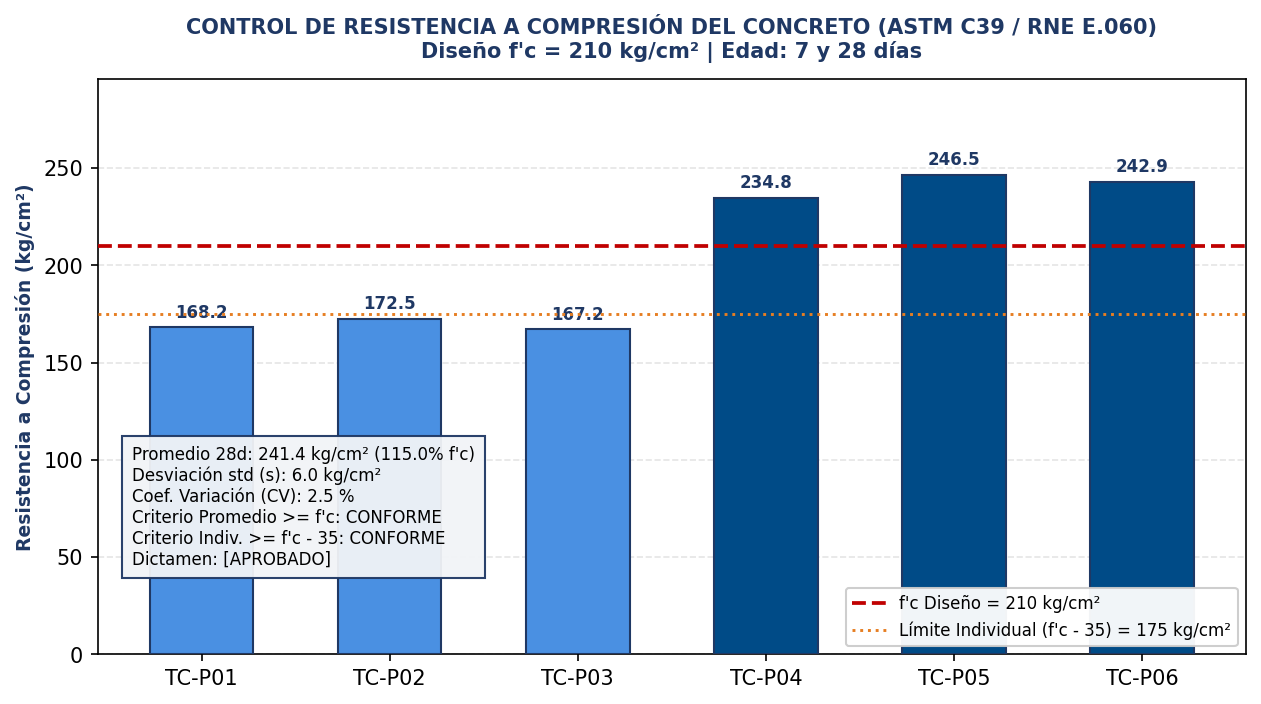

In [2]:
datos_probetas = [
    # 3 Probetas de control temprano (7 días ± 6 h)
    {"codigo": "TC-P01", "edad_dias": 7,  "diametro_mm": 150.2, "altura_mm": 300.5, "carga_rotura_kgf": 29800.0, "tipo_falla": "Tipo 1 (Cono)", "sistema_refrentado": "Yeso de alta resistencia (C617)"},
    {"codigo": "TC-P02", "edad_dias": 7,  "diametro_mm": 149.8, "altura_mm": 300.0, "carga_rotura_kgf": 30400.0, "tipo_falla": "Tipo 2 (Cono y división)", "sistema_refrentado": "Yeso de alta resistencia (C617)"},
    {"codigo": "TC-P03", "edad_dias": 7,  "diametro_mm": 150.0, "altura_mm": 301.0, "carga_rotura_kgf": 29550.0, "tipo_falla": "Tipo 1 (Cono)", "sistema_refrentado": "Yeso de alta resistencia (C617)"},
    # 3 Probetas de aceptación de diseño (28 días ± 20 h)
    {"codigo": "TC-P04", "edad_dias": 28, "diametro_mm": 150.0, "altura_mm": 300.5, "carga_rotura_kgf": 41500.0, "tipo_falla": "Tipo 1 (Cono)", "sistema_refrentado": "Yeso de alta resistencia (C617)"},
    {"codigo": "TC-P05", "edad_dias": 28, "diametro_mm": 150.4, "altura_mm": 300.0, "carga_rotura_kgf": 43800.0, "tipo_falla": "Tipo 1 (Cono)", "sistema_refrentado": "Yeso de alta resistencia (C617)"},
    {"codigo": "TC-P06", "edad_dias": 28, "diametro_mm": 149.6, "altura_mm": 299.5, "carga_rotura_kgf": 42700.0, "tipo_falla": "Tipo 3 (Columna)", "sistema_refrentado": "Yeso de alta resistencia (C617)"},
]

briqueta = CompresionBriquetas(
    probetas_datos=datos_probetas,
    fc_diseno_kg_cm2=210.0,
    edad_control_dias=28,
    fecha_vaciado="2026-10-14",
    fecha_rotura="2026-11-11",
)

display(briqueta.df)
print("\n" + briqueta.diagnostico_tecnico())
graficar_rotura_compresion(briqueta, guardar_ruta=DIR_SALIDA / "TC-11_Curva_Compresion_fc210.png", mostrar=True)

ruta_xlsx = exportar_ficha_compresion_concreto_excel(briqueta, DIR_SALIDA / "TC-11_Ficha_Rotura_fc210.xlsx", grupo="Brigada TC")
print(f"\n[OK] Ficha Excel de compresión generada: {ruta_xlsx}")

---
## 📝 3. Conclusiones Estructurales